# 04 — Part 2: association of five maternal factors with infant death

**Goal.** Estimate, one factor at a time, how much pre-pregnancy hypertension, pre-pregnancy diabetes, pre-pregnancy BMI class, smoking before pregnancy and the interval since the last pregnancy change the risk of death before age one, after adjustment for confounders chosen from a DAG.

**Thesis part.** Part 2 (association). Plan: `plan/analysis_plan.md`, section 4. Methods and pass/fail rules were fixed before any result.

**Status.** Only the method is here so far: the model code, its check on synthetic data, and the DAG check. The analysis on the real data comes next.

**Inputs.** For now none (synthetic data only). Later: `data/parquet/cohort_<year>.parquet`.

**Outputs.** Later: `reports/part2_results.csv` and forest plots.

**How to run.** Run all cells (about 10 seconds).

**Terms.**
- *Risk ratio (RR)*: the risk of death with the factor divided by the risk without it.
- *Risk difference (RD)*: the extra deaths per 1,000 births caused by the factor, if the association is causal.
- *Confounder*: a cause of both the factor and death; we adjust for it.

## 1. Setup

`REBUILD = True` rebuilds the analysis table from the Parquet files (about 3 minutes). With `False`, a saved table is reused.

In [1]:
REBUILD = False
MI_M = 20          # number of imputations
MI_TEST = False    # True: one cohort, 2 imputations, saved apart (quick test)

In [3]:
import gc
import time
from dataclasses import dataclass, field
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd().parent
PARQUET = ROOT / "data" / "parquet"
WORK = ROOT / "data" / "part2"          # ignored by Git
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
SEED = 20261123
COHORTS = list(range(2016, 2024))
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_width_chars(200); pl.Config.set_float_precision(4)


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)

## 2. Modified Poisson regression on covariate-pattern counts

Modified Poisson regression (log link, robust SE) fitted on covariate-pattern counts.

**Why counts.** every covariate in Part 2 is a category. Births with the same
categories share one predicted risk mu. So the model can be fitted on one row
per pattern, with n = births and d = deaths in that pattern, instead of on
millions of single births. Estimates are identical.

**Robust (sandwich, HC0) covariance, exact from counts:**

    bread  A = sum_g n_g * mu_g * x_g x_g'
    meat   B = sum_g [ d_g (1 - mu_g)^2 + (n_g - d_g) mu_g^2 ] x_g x_g'
    cov    = A^-1 B A^-1
(the bracket is the sum of squared single-birth residuals y - mu in the pattern).
Zou (2004) "modified Poisson" = Poisson log-link model + this robust covariance.

In [4]:
def design(rows: dict, columns: list[str], reference: dict) -> tuple[np.ndarray, list[str]]:
    """Intercept + one 0/1 column per non-reference category.

    rows: {column: numpy array of category codes (strings or ints), one per pattern}
    reference: {column: reference category}
    """
    n = len(next(iter(rows.values())))
    mats, names = [np.ones((n, 1))], ["intercept"]
    for col in columns:
        vals = rows[col]
        present = sorted(set(vals.tolist()), key=str)
        # If the reference class is absent (e.g. parity 1 among births after a live birth),
        # the lowest present class becomes the reference; otherwise the columns are collinear.
        ref = reference[col] if reference[col] in present else present[0]
        cats = [c for c in present if c != ref]
        for c in cats:
            mats.append((vals == c).astype(np.float64)[:, None])
            names.append(f"{col}={c}")
    return np.hstack(mats), names


def fit(X: np.ndarray, n: np.ndarray, d: np.ndarray, max_iter: int = 100, tol: float = 1e-10) -> dict:
    """Fit log mu = X beta on pattern counts (n births, d deaths). Returns beta and covariances."""
    n, d = n.astype(np.float64), d.astype(np.float64)
    beta = np.zeros(X.shape[1])
    beta[0] = np.log(d.sum() / n.sum())

    def loglik(b):
        with np.errstate(over="ignore", invalid="ignore"):
            eta = X @ b
            return np.sum(d * eta - n * np.exp(eta))

    ll = loglik(beta)
    for it in range(max_iter):
        mu = np.exp(X @ beta)
        score = X.T @ (d - n * mu)
        A = (X * (n * mu)[:, None]).T @ X
        step = np.linalg.solve(A, score)
        # Step-halving: a full Newton step can overshoot when some patterns have a very high risk.
        t = 1.0
        while True:
            ll_new = loglik(beta + t * step)
            if np.isfinite(ll_new) and ll_new >= ll - 1e-9 * abs(ll):
                break
            t /= 2
            if t < 1e-10:
                raise RuntimeError("modified Poisson: step-halving failed")
        beta, ll = beta + t * step, ll_new
        if np.max(np.abs(t * step)) < tol:
            break
    else:
        raise RuntimeError("modified Poisson did not converge")
    mu = np.exp(X @ beta)
    A = (X * (n * mu)[:, None]).T @ X
    B = (X * (d * (1 - mu) ** 2 + (n - d) * mu ** 2)[:, None]).T @ X
    A_inv = np.linalg.inv(A)
    return {"beta": beta, "cov_robust": A_inv @ B @ A_inv, "cov_model": A_inv, "iterations": it + 1,
            "max_mu": float(mu.max())}


def rr(result: dict, names: list[str], term: str) -> dict:
    """Risk ratio, 95% CI and SE(log RR) for one coefficient."""
    j = names.index(term)
    b, se = result["beta"][j], np.sqrt(result["cov_robust"][j, j])
    return {"term": term, "log_rr": b, "se": se, "rr": np.exp(b),
            "rr_lo": np.exp(b - 1.96 * se), "rr_hi": np.exp(b + 1.96 * se)}


def standardized_rd(result: dict, X: np.ndarray, n: np.ndarray, exposed: np.ndarray,
                    exposure_cols: list[int], draws: int = 1000, seed: int = 20261123) -> dict:
    """g-computation risk difference per 1,000 births, standardized to the exposed patterns.

    For births in exposed patterns: predicted risk as observed minus predicted risk
    with the exposure columns set to 0 (reference). CI from coefficient draws
    from N(beta, robust covariance).
    """
    Xe, ne = X[exposed], n[exposed].astype(np.float64)
    X0 = Xe.copy()
    X0[:, exposure_cols] = 0.0

    def rd(beta):
        return 1000 * np.sum(ne * (np.exp(Xe @ beta) - np.exp(X0 @ beta))) / ne.sum()

    rng = np.random.default_rng(seed)
    sims = rng.multivariate_normal(result["beta"], result["cov_robust"], size=draws)
    vals = np.array([rd(b) for b in sims])
    return {"rd_per_1000": rd(result["beta"]), "rd_lo": np.percentile(vals, 2.5), "rd_hi": np.percentile(vals, 97.5),
            "rd_sd": float(np.std(vals))}

## 3. Check against statsmodels on synthetic data

**What.** We simulate 300,000 births with known effects, fit the same model (a) with statsmodels on single births and (b) with our function on pattern counts, and compare.

**Pass rule.** Coefficients, robust standard errors and the g-computation risk difference must agree to better than 1e-8. No real data is used.

In [5]:
rng = np.random.default_rng(1)
N = 300_000
age, race = rng.integers(1, 6, N), rng.integers(1, 4, N)
expo = (rng.random(N) < 0.03 + 0.01 * (age > 3)).astype(int)
y = (rng.random(N) < 0.004 * np.exp(0.6 * expo + 0.15 * (age - 3) + 0.3 * (race == 2))).astype(float)

Xi = np.column_stack([np.ones(N)] + [(age == a).astype(float) for a in range(2, 6)]
                     + [(race == r).astype(float) for r in (2, 3)] + [expo.astype(float)])
ref = sm.GLM(y, Xi, family=sm.families.Poisson()).fit(cov_type="HC0")

g = pl.DataFrame({"age": age, "race": race, "expo": expo, "y": y}).group_by("age", "race", "expo") \
      .agg(n=pl.len(), d=pl.col("y").sum())
X, names = design({c: g[c].to_numpy() for c in ("age", "race", "expo")}, ["age", "race", "expo"],
                  {"age": 1, "race": 1, "expo": 0})
res = fit(X, g["n"].to_numpy(), g["d"].to_numpy())
order = [names.index(t) for t in ["intercept", "age=2", "age=3", "age=4", "age=5", "race=2", "race=3", "expo=1"]]

beta_diff = np.max(np.abs(res["beta"][order] - ref.params))
se_diff = np.max(np.abs(np.sqrt(np.diag(res["cov_robust"]))[order] / ref.bse - 1))
exposed = g["expo"].to_numpy() == 1
rd_grouped = standardized_rd(res, X, g["n"].to_numpy(), exposed, [names.index("expo=1")], draws=100)["rd_per_1000"]
Xe = Xi[expo == 1]
X0 = Xe.copy()
X0[:, -1] = 0
rd_single = 1000 * np.mean(np.exp(Xe @ ref.params) - np.exp(X0 @ ref.params))

print(f"beta diff {beta_diff:.1e}, SE diff {se_diff:.1e}, RD {rd_grouped:.6f} vs {rd_single:.6f}, "
      f"RR {rr(res, names, 'expo=1')['rr']:.4f}")
assert beta_diff < 1e-8 and se_diff < 1e-8 and abs(rd_grouped - rd_single) < 1e-8
print("PASS")
pl.DataFrame({"check": ["modified Poisson on pattern counts vs statsmodels (synthetic data)"], "beta_max_diff": [beta_diff],
              "se_max_rel_diff": [se_diff], "rd_abs_diff": [abs(rd_grouped - rd_single)], "status": ["PASS"]}).write_csv(REPORTS / "part2_method_check.csv")

beta diff 1.3e-12, SE diff 4.7e-12, RD 3.656052 vs 3.656052, RR 1.7947
PASS


**Result. PASS.** The two fits agree: the coefficients differ by about 1e-12, the robust standard errors by about 5e-12, and the risk differences are equal. Our function uses 30 pattern rows instead of 300,000 single births, so it can fit all 30 million births with very little memory.

## 4. DAG check: are the planned adjustment sets valid?

**What.** Each exposure has a DAG (directed acyclic graph) in `plan/dags/`: a drawing of our assumptions about what causes what. For each exposure we test the planned confounder set with the *back-door criterion*:
- no variable in the set may be caused by the exposure (it would be a mediator);
- the set must block every non-causal path from the exposure to death.

We also test that adding gestational age (GA) makes each set invalid. GA is caused by the exposure and shares unmeasured causes with death, so adjusting for it opens a collider path.

**How.** A path is blocked if the two ends are *d-separated*. We test d-separation with the standard moralization method: keep the exposure, outcome, set and their ancestors; join parents that share a child; drop edge directions; remove the set; the two ends must then be disconnected. Before the test, the exposure's outgoing edges are removed, so that only back-door paths remain.

**Pass rule.** Every planned set is valid, and every set plus GA is invalid. A DAG is an assumption: this check shows that the sets follow from the drawn DAGs, not that the DAGs are true.

In [6]:
import re
from itertools import combinations
from pathlib import Path

DAGS = Path.cwd().parent / "plan" / "dags"


def read_dag(path):
    """Edges of a dagitty file (the simple 'A -> { B C }' and 'A -> B' forms used in plan/dags)."""
    text = re.sub(r"//.*", "", path.read_text())
    edges = set()
    for a, b in re.findall(r"(\w+)\s*->\s*(\{[^}]*\}|\w+)", text):
        for t in b.strip("{}").split():
            edges.add((a, t))
    return edges


def ancestors(edges, nodes):
    out, todo = set(nodes), list(nodes)
    while todo:
        n = todo.pop()
        for a, b in edges:
            if b == n and a not in out:
                out.add(a)
                todo.append(a)
    return out


def d_separated(edges, x, y, z):
    keep = ancestors(edges, {x, y} | set(z))
    sub = {(a, b) for a, b in edges if a in keep and b in keep}
    und = {frozenset(e) for e in sub}
    for child in keep:                                   # moralize: join parents of a common child
        parents = [a for a, b in sub if b == child]
        und |= {frozenset(p) for p in combinations(parents, 2)}
    und = {e for e in und if not (e & set(z))}
    seen, todo = {x}, [x]
    while todo:
        n = todo.pop()
        for e in und:
            if n in e:
                (m,) = e - {n} if len(e) == 2 else (n,)
                if m not in seen:
                    seen.add(m)
                    todo.append(m)
    return y not in seen


def descendants(edges, x):
    out, todo = set(), [x]
    while todo:
        n = todo.pop()
        for a, b in edges:
            if a == n and b not in out:
                out.add(b)
                todo.append(b)
    return out


def backdoor_valid(edges, x, y, z):
    if set(z) & descendants(edges, x):
        return False
    return d_separated({(a, b) for a, b in edges if a != x}, x, y, z)


BASE = ["Age", "Race", "Nativity", "Edu", "Pay", "Parity", "Year"]
PLANNED = {
    "hypertension": ("HTN", BASE + ["Smoke0", "BMI"]),
    "diabetes": ("DM", BASE + ["Smoke0", "BMI"]),
    "bmi": ("BMI", BASE + ["Smoke0"]),
    "smoking": ("Smoke0", BASE),
    "interval": ("IPI", BASE + ["Smoke0", "PriorLoss", "PriorDead", "PrevPTB"]),
}
rows = []
for name, (x, z) in PLANNED.items():
    e = read_dag(DAGS / f"dag_{name}.dagitty")
    rows.append({"exposure": name, "set": ", ".join(z), "valid": backdoor_valid(e, x, "Death", z),
                 "valid_with_GA": backdoor_valid(e, x, "Death", z + ["GA"]),
                 "unadjusted_valid": backdoor_valid(e, x, "Death", [])})
dag_check = pl.DataFrame(rows)
print("DAG CHECK:", "PASS" if dag_check["valid"].all() and not dag_check["valid_with_GA"].any() else "FAIL")
dag_check
dag_check.write_csv(REPORTS / "part2_dag_check.csv")

DAG CHECK: PASS


**Result.** The check prints PASS when every planned set is valid and every set with gestational age added is invalid. `unadjusted_valid = false` shows that each exposure does need adjustment.

**Self-test of the checker.** Below, two cases with a known answer: in a fork `C → X, C → Y` the empty set is invalid and `{C}` is valid; in a collider `X → M ← U → Y` with `X → Y`, adding `M` is invalid.

In [7]:
fork = {("C", "X"), ("C", "Y"), ("X", "Y")}
collider = {("X", "M"), ("U", "M"), ("U", "Y"), ("X", "Y")}
assert not backdoor_valid(fork, "X", "Y", []) and backdoor_valid(fork, "X", "Y", ["C"])
assert backdoor_valid(collider, "X", "Y", []) and not backdoor_valid(collider, "X", "Y", ["M"])
print("checker self-test PASS")

checker self-test PASS


## 5. Analysis table: one row per birth, all items as small category codes

**What.** For every resident singleton birth (`RESTATUS` < 4, `DPLURAL` = 1), turn the CDC text codes into the categories fixed in the plan (change log, 24 Nov 2026). Unknown codes, and items whose reporting flag is not 1, become missing. Save the result to `data/part2/births.parquet` (ignored by Git).

**Outcomes.** `d1` = death before 365 days; `dneo` = death at 0–27 days; `dpost` = death at 28–364 days; `dacc` = accident death without suffocation (`UCODR130` 141–145, 148–151; the negative control).

**Interval since the last pregnancy.** `ILP_R` counts months up to *this birth*, so we subtract this pregnancy's length: `COMBGEST` weeks × 7 / 30.44, rounded. `ilp_status`: 0 = no earlier pregnancy (888), 1 = known (4–300), 2 = unknown (999), 3 = plural code (000–003).

In [8]:
GEST_M = "round(CAST(COMBGEST AS INT) * 7 / 30.44)"


def interval_class(col):
    # months to this birth minus this pregnancy -> classes; reference 4 = 18-23 months
    m = f"(CAST({col} AS INT) - {GEST_M})"
    return f"""CASE WHEN {col} IS NULL OR NOT (CAST({col} AS INT) BETWEEN 4 AND 300) OR COMBGEST IS NULL OR COMBGEST = '99' THEN NULL
                WHEN {m} < 0 THEN NULL WHEN {m} < 6 THEN 1 WHEN {m} < 12 THEN 2 WHEN {m} < 18 THEN 3
                WHEN {m} < 24 THEN 4 WHEN {m} < 60 THEN 5 ELSE 6 END"""


def yn(col, flag):
    return f"CASE WHEN COALESCE({flag}, '1') <> '1' THEN NULL WHEN {col} = 'Y' THEN 1 WHEN {col} = 'N' THEN 0 END"


DERIVED = f"""
SELECT cohort,
  CASE WHEN MAGER9 IN ('1','2') THEN 1 WHEN MAGER9 = '3' THEN 2 WHEN MAGER9 = '4' THEN 3 WHEN MAGER9 = '5' THEN 4
       WHEN MAGER9 = '6' THEN 5 WHEN MAGER9 IN ('7','8','9') THEN 6 END AS age,
  CASE WHEN MRACEHISP IN ('1','2','3','4','5','6','7') THEN CAST(MRACEHISP AS INT) END AS race,
  CASE MBSTATE_REC WHEN '1' THEN 1 WHEN '2' THEN 2 END AS nat,
  CASE WHEN COALESCE(F_MEDUC, '1') <> '1' THEN NULL WHEN MEDUC IN ('1','2') THEN 1 WHEN MEDUC = '3' THEN 2
       WHEN MEDUC IN ('4','5') THEN 3 WHEN MEDUC = '6' THEN 4 WHEN MEDUC IN ('7','8') THEN 5 END AS edu,
  CASE WHEN COALESCE(F_PAY_REC, '1') <> '1' THEN NULL WHEN PAY_REC IN ('1','2','3','4') THEN CAST(PAY_REC AS INT) END AS pay,
  CASE WHEN LBO_REC IN ('1','2','3') THEN CAST(LBO_REC AS INT) WHEN LBO_REC IN ('4','5','6','7','8') THEN 4 END AS par,
  CASE WHEN COALESCE(F_CIGS_0, '1') <> '1' OR CIG_0 IS NULL OR CIG_0 = '99' THEN NULL
       WHEN CAST(CIG_0 AS INT) = 0 THEN 0 ELSE 1 END AS smoke,
  CASE WHEN COALESCE(F_CIGS_0, '1') <> '1' THEN NULL WHEN CIG0_R IN ('0','1','2','3') THEN CAST(CIG0_R AS INT)
       WHEN CIG0_R IN ('4','5') THEN 4 END AS smoke_dose,
  CASE WHEN COALESCE(F_PWGT, '1') <> '1' OR COALESCE(F_M_HT, '1') <> '1' THEN NULL
       WHEN BMI_R IN ('1','2','3','4','5','6') THEN CAST(BMI_R AS INT) END AS bmi,
  {yn("RF_PHYPE", "F_RF_PHYPE")} AS htn,
  {yn("RF_PDIAB", "F_RF_PDIAB")} AS dm,
  {yn("RF_PPB", "F_RF_PPB")} AS ppb,
  CASE WHEN PRIORTERM IS NULL OR PRIORTERM = '99' THEN NULL WHEN CAST(PRIORTERM AS INT) = 0 THEN 0 ELSE 1 END AS priorloss,
  CASE WHEN PRIORDEAD IS NULL OR PRIORDEAD = '99' THEN NULL WHEN CAST(PRIORDEAD AS INT) = 0 THEN 0 ELSE 1 END AS priordead,
  CASE WHEN ILP_R = '888' THEN 0 WHEN ILP_R = '999' OR ILP_R IS NULL THEN 2
       WHEN CAST(ILP_R AS INT) BETWEEN 4 AND 300 THEN 1 ELSE 3 END AS ilp_status,
  {interval_class("ILP_R")} AS ipi,
  {interval_class("ILLB_R")} AS ilb,
  CASE WHEN COMBGEST IS NULL OR COMBGEST = '99' THEN NULL WHEN CAST(COMBGEST AS INT) < 28 THEN 1
       WHEN CAST(COMBGEST AS INT) < 32 THEN 2 WHEN CAST(COMBGEST AS INT) < 34 THEN 3 WHEN CAST(COMBGEST AS INT) < 37 THEN 4
       WHEN CAST(COMBGEST AS INT) < 39 THEN 5 WHEN CAST(COMBGEST AS INT) < 41 THEN 6 ELSE 7 END AS ga,
  death::INT AS d1,
  (death AND CAST(AGEDX AS INT) < 28)::INT AS dneo,
  (death AND CAST(AGEDX AS INT) >= 28)::INT AS dpost,
  (death AND UCODR130 IN ('141','142','143','144','145','148','149','150','151'))::INT AS dacc
FROM read_parquet('{PARQUET}/cohort_*.parquet', union_by_name = true)
WHERE CAST(RESTATUS AS INT) < 4 AND DPLURAL = '1'
"""

BIRTHS = WORK / "births.parquet"
if REBUILD or not BIRTHS.exists():
    WORK.mkdir(parents=True, exist_ok=True)
    con = duckdb.connect()
    con.sql("SET threads TO 4")
    # small integer types keep the file and memory small
    cast = ", ".join(f"CAST({c} AS TINYINT) AS {c}" for c in
                     ["age", "race", "nat", "edu", "pay", "par", "smoke", "smoke_dose", "bmi", "htn", "dm", "ppb",
                      "priorloss", "priordead", "ilp_status", "ipi", "ilb", "ga", "d1", "dneo", "dpost", "dacc"])
    con.sql(f"COPY (SELECT CAST(cohort AS SMALLINT) AS cohort, {cast} FROM ({DERIVED})) TO '{BIRTHS}' (FORMAT parquet)")
    con.close()
    log("built", BIRTHS.name)
duckdb.sql(f"""SELECT cohort, COUNT(*) AS births, SUM(d1)::BIGINT AS deaths, SUM(dneo)::BIGINT AS neonatal, SUM(dpost)::BIGINT AS postneonatal,
                      SUM(dacc)::BIGINT AS accident FROM '{BIRTHS}' GROUP BY cohort ORDER BY cohort""").pl()

cohort,births,deaths,neonatal,postneonatal,accident
i16,i64,i64,i64,i64,i64
2016,3810149,19641,12574,7067,258
2017,3723273,19026,12219,6807,215
2018,3664651,18510,11899,6611,199
2019,3623963,17847,11437,6410,191
2020,3498335,16786,10710,6076,234
2021,3547198,17496,10765,6731,254
2022,3550380,17840,11036,6804,228
2023,3482971,17355,11041,6314,200


**Result.** The table shows the resident singleton births and deaths per cohort. Neonatal + postneonatal deaths = all deaths. The accident deaths (negative control) are about 200 per cohort.

## 6. The five exposures and their confounder sets

**What.** Each exposure gets its own population, its own reference category and its own confounder set, exactly as in the plan (section 4) and the DAG check above. `where` limits the population: the interval analysis uses only births with an earlier pregnancy.

**Pattern counts.** For each cohort we count births and deaths in every combination of the exposure and its confounders. A *pattern* is one such combination. The model is fitted on these counts (section 2).

In [9]:
REF = {"age": 3, "race": 1, "nat": 1, "edu": 2, "pay": 2, "par": 1, "smoke": 0, "smoke_dose": 0, "bmi": 2,
       "htn": 0, "dm": 0, "ppb": 0, "priorloss": 0, "priordead": 0, "ipi": 4, "ilb": 4, "ga": 6, "cohort": 2016}
BASE = ["age", "race", "nat", "edu", "pay", "par"]


@dataclass
class Exposure:
    name: str
    col: str
    confounders: list
    where: str = "TRUE"
    labels: dict = field(default_factory=dict)


EXPOSURES = [
    Exposure("hypertension", "htn", BASE + ["smoke", "bmi"], labels={1: "yes"}),
    Exposure("diabetes", "dm", BASE + ["smoke", "bmi"], labels={1: "yes"}),
    Exposure("bmi", "bmi", BASE + ["smoke"], labels={1: "<18.5", 3: "25-29.9", 4: "30-34.9", 5: "35-39.9", 6: ">=40"}),
    Exposure("smoking", "smoke", BASE, labels={1: "any"}),
    Exposure("interval", "ipi", BASE + ["smoke", "priorloss", "priordead", "ppb"], where="ilp_status = 1",
             labels={1: "<6 mo", 2: "6-11 mo", 3: "12-17 mo", 5: "24-59 mo", 6: ">=60 mo"}),
]
SENSITIVITY = [
    Exposure("smoking_dose", "smoke_dose", BASE, labels={1: "1-5/day", 2: "6-10/day", 3: "11-20/day", 4: ">=21/day"}),
    Exposure("bmi_multipara_plus_interval", "bmi", BASE + ["smoke", "ipi"], where="ilp_status = 1",
             labels={1: "<18.5", 3: "25-29.9", 4: "30-34.9", 5: "35-39.9", 6: ">=40"}),
    Exposure("interval_from_live_birth", "ilb", BASE + ["smoke", "priorloss", "priordead", "ppb"], where="ilb IS NOT NULL",
             labels={1: "<6 mo", 2: "6-11 mo", 3: "12-17 mo", 5: "24-59 mo", 6: ">=60 mo"}),
]
OUTCOMES = {"infant": ("d1", "n"), "neonatal": ("dneo", "n"), "postneonatal": ("dpost", "n28")}


def patterns(e: Exposure, extra=(), by_cohort=True):
    cols = [e.col] + e.confounders + list(extra)
    keep = " AND ".join(f"{c} IS NOT NULL" for c in cols)
    grp = ", ".join((["cohort"] if by_cohort else []) + cols)
    q = f"""SELECT {grp}, COUNT(*) AS n, SUM(d1)::BIGINT AS d1, SUM(dneo)::BIGINT AS dneo, SUM(dpost)::BIGINT AS dpost, SUM(dacc)::BIGINT AS dacc
            FROM '{BIRTHS}' WHERE {e.where} AND {keep} GROUP BY ALL"""
    return duckdb.sql(q).pl().with_columns(n28=pl.col("n") - pl.col("dneo"))

## 7. Who is exposed? Births and deaths in each exposure class

**What.** Pooled over 2016–2023, in each analysis population (complete case): the number of births and infant deaths in each class, and the crude death rate per 1,000.

**Why.** It shows how much data each estimate rests on. Crude rates are *not* the result: they are not adjusted for confounders.

In [10]:
desc = []
for e in EXPOSURES:
    g = patterns(e, by_cohort=False).group_by(e.col).agg(pl.col("n").sum(), pl.col("d1").sum()).sort(e.col)
    for r in g.iter_rows(named=True):
        desc.append({"exposure": e.name, "class": e.labels.get(r[e.col], f"reference ({r[e.col]})"),
                     "births": r["n"], "deaths": r["d1"], "crude_per_1000": 1000 * r["d1"] / r["n"]})
desc = pl.DataFrame(desc)
desc.write_csv(REPORTS / "part2_exposure_counts.csv")
desc

exposure,class,births,deaths,crude_per_1000
str,str,i64,i64,f64
"""hypertension""","""reference (0)""",26627607,121288,4.5550
"""hypertension""","""yes""",643005,5730,8.9113
"""diabetes""","""reference (0)""",26991230,124117,4.5984
"""diabetes""","""yes""",279382,2901,10.3836
"""bmi""","""<18.5""",823557,4358,5.2917
"""bmi""","""reference (2)""",11142353,43218,3.8787
"""bmi""","""25-29.9""",7351454,32280,4.3910
"""bmi""","""30-34.9""",4290032,22834,5.3226
"""bmi""","""35-39.9""",2140917,13232,6.1805


**Result.** In resident singletons with complete data:
- pre-pregnancy hypertension: 2.4% of births (643,005); diabetes: 1.0% (279,382); smoking before pregnancy: 7.1% (1,971,532);
- BMI: 41% normal, 27% overweight, 16% / 8% / 6% obesity class I / II / III, 3% underweight;
- interval: 16.4 million births with an earlier pregnancy and a known interval.

The crude death rates already point the same way as the plan expected: about double for hypertension (8.9 vs 4.6 per 1,000), diabetes (10.4 vs 4.6) and smoking (9.1 vs 4.5); rising with BMI from 3.9 (normal) to 7.4 (≥40); and a U-shape for the interval (6.0 below 6 months, 3.9 at 18–23 months, 4.7 at 60 months or more). These numbers are **not** adjusted. Every class has thousands of deaths, so the estimates below are precise.

## 8. Pre-set check 5: is missing information linked to death?

**Rule (plan, check 5).** For each item, compare the infant death rate of births *with* and *without* a value. If they differ by more than 20% (relative), complete-case results may be biased, and multiple imputation is required as a sensitivity analysis. BMI and education already triggered this rule in Table 1. Here we test all Part 2 items, in resident singletons. For the interval, the population is births whose earlier-pregnancy status is not "none".

In [11]:
ITEMS = ["age", "race", "nat", "edu", "pay", "par", "smoke", "bmi", "htn", "dm", "ppb", "priorloss", "priordead"]
q = " UNION ALL ".join(
    f"""SELECT '{c}' AS item, ({c} IS NULL) AS missing, COUNT(*) AS births, SUM(d1)::BIGINT AS deaths FROM '{BIRTHS}' GROUP BY 2"""
    for c in ITEMS)
q += f""" UNION ALL SELECT 'interval' AS item, (ipi IS NULL) AS missing, COUNT(*), SUM(d1)::BIGINT FROM '{BIRTHS}'
          WHERE ilp_status IN (1, 2) GROUP BY 2"""
m = duckdb.sql(q).pl().with_columns(rate=1000 * pl.col("deaths") / pl.col("births"))
miss = (m.filter(~pl.col("missing")).select("item", pl.col("births").alias("births_with"), pl.col("rate").alias("rate_with"))
        .join(m.filter(pl.col("missing")).select("item", pl.col("births").alias("births_missing"), pl.col("rate").alias("rate_missing")),
              on="item", how="left")
        .with_columns(pct_missing=100 * pl.col("births_missing") / (pl.col("births_with") + pl.col("births_missing")),
                      relative_diff=(pl.col("rate_missing") / pl.col("rate_with") - 1))
        .with_columns(triggers_mi=pl.col("relative_diff").abs() > 0.20))
miss.write_csv(REPORTS / "part2_missing_check.csv")
miss.sort("pct_missing", descending=True)

item,births_with,rate_with,births_missing,rate_missing,pct_missing,relative_diff,triggers_mi
str,i64,f64,i64,f64,f64,f64,bool
"""age""",28900920,4.9999,null,null,null,null,null
"""interval""",16424449,4.6804,3324857,7.3080,16.8353,0.5614,true
"""bmi""",28113552,4.7929,787368,12.3894,2.7244,1.5849,true
"""edu""",28348480,4.8530,552440,12.5389,1.9115,1.5838,true
"""pay""",28565127,4.9747,335793,7.1383,1.1619,0.4349,true
"""race""",28636663,4.9466,264257,10.7774,0.9144,1.1788,true
"""smoke""",28638605,4.9463,262315,10.8534,0.9076,1.1943,true
"""htn""",28734211,4.9891,166709,6.8503,0.5768,0.3730,true
"""dm""",28734211,4.9891,166709,6.8503,0.5768,0.3730,true


**Result. Check 5 is triggered for every item**, not only for BMI and education. Births with a missing item die 1.4 to 5.7 times as often than births with the item recorded. The likely reason: an incomplete certificate is a marker of a hurried or difficult birth (for example a very preterm baby moved to intensive care).

How much this matters depends on how much is missing:
- **below 1.2% missing** (race, payment, smoking, hypertension, diabetes, parity, earlier-pregnancy items, nativity): complete-case bias is small; these stay complete-case, as the plan says;
- **BMI (2.7%) and education (1.9%)**: multiple imputation, already planned;
- **the interval (16.8% missing, death rate 56% higher when missing)**: this is new and large. Complete-case results for the interval may be biased. On 24 Nov 2026 it was added to the imputation (section 16).

## 9. Fit every model

**What.** For each exposure, each outcome and each cohort: fit the modified Poisson model on the pattern counts, and keep
- the log risk ratio (RR) of each exposure class and its robust variance;
- the g-computation risk difference (RD) per 1,000 births for each class, with the SD of 1,000 coefficient draws.

Postneonatal models use only babies alive at day 28 (`n28`).

**Also fitted here.**
- *Collider demonstration (check 4):* infant death with gestational age added.
- *Sensitivity analyses:* smoking dose; BMI among births with an earlier pregnancy, with the interval added; the interval from the last live birth.
- *Negative control (check 3):* accident deaths, one model on all cohorts with cohort as a covariate.

**Expected run time.** About 10–20 minutes.

In [12]:
def fit_model(g, e, dcol, ncol, extra=(), extra_ref=None, draws=1000):
    """One modified Poisson fit; returns per-class log RR, variance and RD, or None if it fails."""
    cols = [e.col] + e.confounders + list(extra)
    g = g.filter(pl.col(ncol) > 0)
    X, names = design({c: g[c].to_numpy() for c in cols}, cols, {**REF, **(extra_ref or {})})
    try:
        res = fit(X, g[ncol].to_numpy(), g[dcol].to_numpy())
    except (RuntimeError, np.linalg.LinAlgError) as err:
        return {"error": str(err)}
    out, ex = {}, g[e.col].to_numpy()
    for k in e.labels:
        term = f"{e.col}={k}"
        if term not in names:
            continue
        j = names.index(term)
        rd = standardized_rd(res, X, g[ncol].to_numpy(), ex == k, [j], draws=draws, seed=SEED)
        out[k] = {"log_rr": res["beta"][j], "var": res["cov_robust"][j, j], **rd}
    terms = [names.index(f"{e.col}={k}") for k in e.labels if f"{e.col}={k}" in names]
    out["_joint"] = (res["beta"][terms], res["cov_robust"][np.ix_(terms, terms)], [k for k in e.labels if f"{e.col}={k}" in names])
    out["_max_mu"] = res["max_mu"]
    return out


def run(e, outcomes, extra=(), extra_ref=None, analysis="main"):
    rows, joint = [], []
    g_all = patterns(e, extra)
    for c in COHORTS:
        g = g_all.filter(pl.col("cohort") == c)
        for o in outcomes:
            dcol, ncol = OUTCOMES[o]
            r = fit_model(g, e, dcol, ncol, extra, extra_ref)
            if "error" in r:
                rows.append({"analysis": analysis, "exposure": e.name, "outcome": o, "cohort": c, "error": r["error"]})
                continue
            for k in e.labels:
                if k in r:
                    rows.append({"analysis": analysis, "exposure": e.name, "outcome": o, "cohort": c, "class": k,
                                 "label": e.labels[k], **r[k], "max_mu": r["_max_mu"]})
            joint.append({"analysis": analysis, "exposure": e.name, "outcome": o, "cohort": c, "joint": r["_joint"]})
    log("fitted", analysis, e.name)
    return rows, joint


FITS = WORK / "fits.parquet"
JOINT = WORK / "joint.pkl"
if REBUILD or not FITS.exists():
    import pickle
    rows, joint = [], []
    for e in EXPOSURES:
        r, j = run(e, OUTCOMES)
        rows += r; joint += j
        r, j = run(e, ["infant"], extra=["ga"], analysis="collider_ga")
        rows += r; joint += j
        gc.collect()
    for e in SENSITIVITY:
        r, j = run(e, OUTCOMES, analysis="sensitivity")
        rows += r; joint += j
    pl.DataFrame(rows, infer_schema_length=None).write_parquet(FITS)
    JOINT.write_bytes(pickle.dumps(joint))
fits = pl.read_parquet(FITS)
import pickle
joint = pickle.loads(JOINT.read_bytes())
print("fits:", fits.height, "| failed:", fits.filter(pl.col("error").is_not_null()).height if "error" in fits.columns else 0,
      "| largest predicted risk:", round(fits["max_mu"].max(), 4))

fits: 752 | failed: 0 | largest predicted risk: 1.2276


**Result.** The line above shows how many class estimates were fitted, how many models failed (they should be 0), and the largest predicted risk in any pattern. A log-link model must keep every predicted risk below 1, and here it is far below 1.

## 10. Pooled results over the 8 cohorts

**What.**
- **Pooled RR:** inverse-variance (fixed-effect) pooling of the 8 per-cohort log RRs. *Cochran's Q* and *I²* measure how much the cohorts disagree (I² = share of variation beyond chance). The DerSimonian–Laird random-effects RR is also shown, and it is the main result when I² > 50% (check 2).
- **Pooled RD** per 1,000 births: inverse-variance pooling of the per-cohort g-computation RDs.
- **E-value:** how strong an unmeasured confounder would have to be (its RR with both exposure and death) to explain away the RR (`evalue`) or to move its CI to 1 (`evalue_ci`).
- **Direction (check 1):** in how many of the 8 cohorts the RR is on the same side of 1 as the pooled RR.
- **Joint p-value:** one Wald test per exposure and outcome (all classes together), then Holm adjustment over the 15 main tests.

In [13]:
def evalue(rr):
    rr = 1 / rr if rr < 1 else rr
    return rr + np.sqrt(rr * (rr - 1))


def pool_classes(df):
    out = []
    for key, g in df.group_by(["analysis", "exposure", "outcome", "class", "label"], maintain_order=True):
        b, v = g["log_rr"].to_numpy(), g["var"].to_numpy()
        w = 1 / v
        bf, sef = np.sum(w * b) / w.sum(), np.sqrt(1 / w.sum())
        Q = float(np.sum(w * (b - bf) ** 2)); k = len(b)
        I2 = max(0.0, (Q - (k - 1)) / Q) if Q > 0 else 0.0
        tau2 = max(0.0, (Q - (k - 1)) / (w.sum() - np.sum(w ** 2) / w.sum()))
        wr = 1 / (v + tau2)
        br, ser = np.sum(wr * b) / wr.sum(), np.sqrt(1 / wr.sum())
        rd, rdv = g["rd_per_1000"].to_numpy(), g["rd_sd"].to_numpy() ** 2
        wd = 1 / rdv
        rdf, rdse = np.sum(wd * rd) / wd.sum(), np.sqrt(1 / wd.sum())
        rr, lo, hi = np.exp(bf), np.exp(bf - 1.96 * sef), np.exp(bf + 1.96 * sef)
        main_random = I2 > 0.5
        m_rr = np.exp(br) if main_random else rr
        m_lo, m_hi = (np.exp(br - 1.96 * ser), np.exp(br + 1.96 * ser)) if main_random else (lo, hi)
        out.append(dict(zip(["analysis", "exposure", "outcome", "class", "label"], key)) | {
            "cohorts": k, "rr_fixed": rr, "rr_fixed_lo": lo, "rr_fixed_hi": hi,
            "rr_random": np.exp(br), "rr_random_lo": np.exp(br - 1.96 * ser), "rr_random_hi": np.exp(br + 1.96 * ser),
            "Q": Q, "I2": I2, "main_model": "random" if main_random else "fixed",
            "rr": m_rr, "rr_lo": m_lo, "rr_hi": m_hi,
            "rd_per_1000": rdf, "rd_lo": rdf - 1.96 * rdse, "rd_hi": rdf + 1.96 * rdse,
            "evalue": evalue(m_rr), "evalue_ci": 1.0 if m_lo <= 1 <= m_hi else evalue(m_lo if m_rr > 1 else m_hi),
            "same_direction": int(np.sum(np.sign(b) == np.sign(np.log(m_rr)))),
        })
    return pl.DataFrame(out)


def joint_p(analysis, exposure, outcome):
    items = [j["joint"] for j in joint if (j["analysis"], j["exposure"], j["outcome"]) == (analysis, exposure, outcome)]
    classes = sorted(set.intersection(*[set(it[2]) for it in items]))
    W, Wb = 0, 0
    for b, V, ks in items:
        idx = [ks.index(k) for k in classes]
        Wi = np.linalg.inv(V[np.ix_(idx, idx)])
        W, Wb = W + Wi, Wb + Wi @ b[idx]
    bp = np.linalg.solve(W, Wb)
    chi2 = float(bp @ W @ bp)
    return chi2, len(classes), float(stats.chi2.sf(chi2, len(classes)))


good = fits.filter(pl.col("log_rr").is_not_null())
pooled = pool_classes(good)
jp = pl.DataFrame([dict(zip(["analysis", "exposure", "outcome"], k)) | dict(zip(["chi2", "df", "p_joint"], joint_p(*k)))
                   for k in pooled.select("analysis", "exposure", "outcome").unique(maintain_order=True).iter_rows()])
main_p = jp.filter(pl.col("analysis") == "main")
main_p = main_p.with_columns(p_holm=pl.Series(multipletests(main_p["p_joint"].to_numpy(), method="holm")[1]))
jp = jp.join(main_p.select("analysis", "exposure", "outcome", "p_holm"), on=["analysis", "exposure", "outcome"], how="left")
pooled = pooled.join(jp, on=["analysis", "exposure", "outcome"], how="left")
pooled.write_csv(REPORTS / "part2_pooled_all.csv")
good.drop("max_mu").write_csv(REPORTS / "part2_by_cohort.csv")
res_main = pooled.filter(pl.col("analysis") == "main").select(
    "exposure", "outcome", "label", "rr", "rr_lo", "rr_hi", "rd_per_1000", "rd_lo", "rd_hi",
    "evalue", "evalue_ci", "I2", "main_model", "same_direction", "p_joint", "p_holm")
res_main.write_csv(REPORTS / "part2_results.csv")
res_main

exposure,outcome,label,rr,rr_lo,rr_hi,rd_per_1000,rd_lo,rd_hi,evalue,evalue_ci,I2,main_model,same_direction,p_joint,p_holm
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,i64,f64,f64
"""hypertension""","""infant""","""yes""",1.4951,1.4547,1.5365,2.9082,2.6657,3.1507,2.3554,2.2680,0.4732,"""fixed""",8,0.0000,0.0000
"""hypertension""","""neonatal""","""yes""",1.5282,1.4769,1.5814,1.9589,1.7653,2.1526,2.4267,2.3161,0.0000,"""fixed""",8,0.0000,0.0000
"""hypertension""","""postneonatal""","""yes""",1.4421,1.3774,1.5099,0.9542,0.8115,1.0969,2.2406,2.0983,0.0522,"""fixed""",8,0.0000,0.0000
"""diabetes""","""infant""","""yes""",1.8411,1.7398,1.9483,4.6722,4.2916,5.0529,3.0856,2.8743,0.5694,"""random""",8,0.0000,0.0000
"""diabetes""","""neonatal""","""yes""",1.9297,1.8440,2.0194,3.3038,2.9949,3.6128,3.2691,3.0914,0.4481,"""fixed""",8,0.0000,0.0000
"""diabetes""","""postneonatal""","""yes""",1.6964,1.5897,1.8103,1.3620,1.1460,1.5780,2.7833,2.5578,0.2009,"""fixed""",8,0.0000,0.0000
"""bmi""","""infant""","""<18.5""",1.1365,1.1016,1.1726,0.6227,0.4602,0.7851,1.5305,1.4362,0.1323,"""fixed""",8,0.0000,0.0000
"""bmi""","""infant""","""25-29.9""",1.0769,1.0614,1.0927,0.3134,0.2500,0.3768,1.3648,1.3167,0.4931,"""fixed""",8,0.0000,0.0000
"""bmi""","""infant""","""30-34.9""",1.2202,1.2004,1.2403,0.9620,0.8804,1.0436,1.7385,1.6909,0.4720,"""fixed""",8,0.0000,0.0000


**Result.** All 15 exposure–outcome tests are clearly significant, also after Holm adjustment (all Holm p < 1e-37).

| Exposure (vs reference) | RR infant death (95% CI) | Extra deaths per 1,000 exposed births | E-value |
|---|---|---|---|
| Hypertension | **1.50** (1.45–1.54) | 2.9 (2.7–3.2) | 2.36 |
| Diabetes | **1.84** (1.74–1.95) | 4.7 (4.3–5.1) | 3.09 |
| BMI ≥40 vs 18.5–24.9 | **1.53** (1.50–1.56) | 2.6 (2.4–2.7) | 2.43 |
| BMI 30–34.9 | 1.22 (1.20–1.24) | 1.0 | 1.74 |
| BMI <18.5 | 1.14 (1.10–1.17) | 0.6 | 1.53 |
| Smoking before pregnancy | **1.68** (1.62–1.74) | 3.6 (3.5–3.8) | 2.75 |
| Interval <6 vs 18–23 months | **1.22** (1.18–1.26) | 1.1 (0.9–1.2) | 1.73 |
| Interval ≥60 months | 1.06 (1.03–1.09) | 0.3 | 1.30 |

How the results compare with the expectations written in the plan:
- **Hypertension and diabetes:** RR > 1, as expected. The plan also expected a stronger effect on neonatal than postneonatal death. This holds, but the difference is small (hypertension 1.53 vs 1.44; diabetes 1.93 vs 1.70).
- **BMI:** a clear dose–response, as expected: 1.08, 1.22, 1.36, 1.53 from overweight to obesity class III. Underweight also raises risk (1.14).
- **Smoking:** as expected, much stronger for postneonatal death (2.02) than for neonatal death (1.41). This fits sudden unexpected infant death.
- **Interval:** a U-shape for infant and neonatal death, as expected. For postneonatal death only short intervals raise risk, and 60 months or more is slightly protective (0.94).

*E-value* example: to explain away the diabetes RR of 1.84, an unmeasured confounder would have to raise both diabetes and death by a factor of 3.1 each, beyond all the confounders we adjusted for.

## 11. Forest plots

**Figure 1** shows the pooled adjusted RR (95% CI) of every exposure class for the three outcomes. **Figure 2** shows the 8 cohort estimates for infant death, for one class per exposure, with the pooled estimate at the bottom. A *forest plot* puts each estimate on one line, so you can see at a glance whether the cohorts agree.

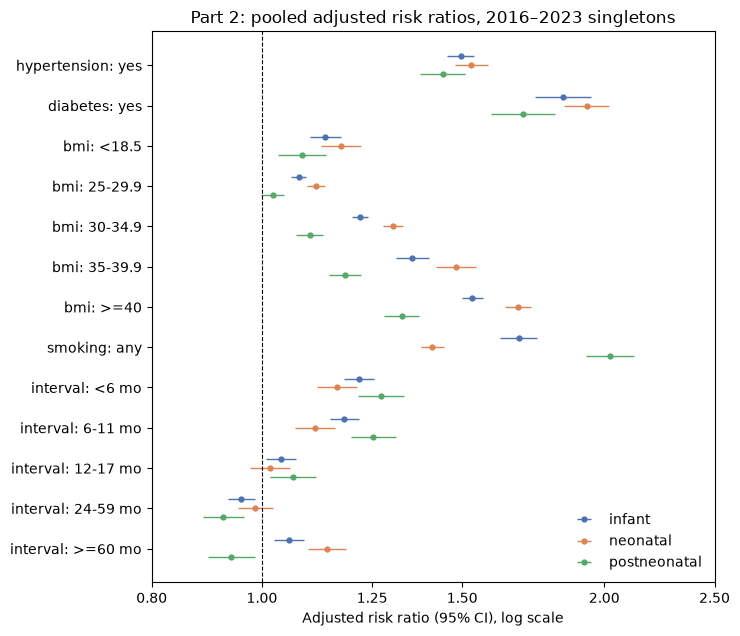

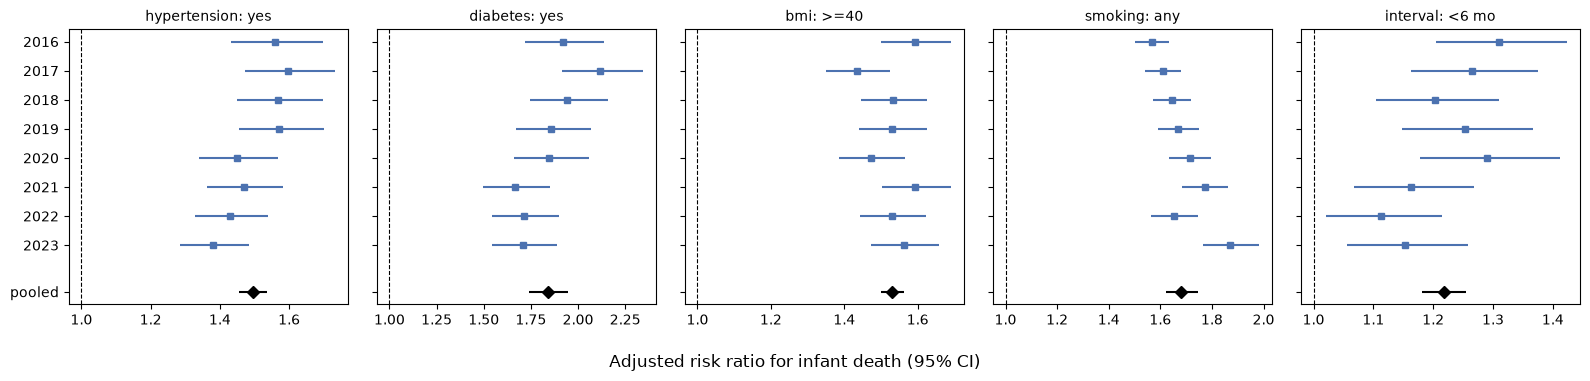

In [14]:
OUT_COL = {"infant": "#4C72B0", "neonatal": "#DD8452", "postneonatal": "#55A868"}
lab = res_main.with_columns(row=pl.col("exposure") + ": " + pl.col("label"))
rows_ = lab["row"].unique(maintain_order=True).to_list()
fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(rows_) + 1))
for i, (o, col) in enumerate(OUT_COL.items()):
    d = lab.filter(pl.col("outcome") == o)
    y = np.array([rows_.index(r) for r in d["row"]]) + (i - 1) * 0.22
    ax.errorbar(d["rr"], y, xerr=[d["rr"] - d["rr_lo"], d["rr_hi"] - d["rr"]], fmt="o", ms=3.5, color=col, label=o, lw=1)
ax.axvline(1, color="k", lw=0.8, ls="--")
ax.set_yticks(range(len(rows_))); ax.set_yticklabels(rows_); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_xticks([0.8, 1, 1.25, 1.5, 2, 2.5]); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter()); ax.minorticks_off()
ax.set_xlabel("Adjusted risk ratio (95% CI), log scale"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Part 2: pooled adjusted risk ratios, 2016–2023 singletons")
fig.tight_layout(); fig.savefig(FIG / "part2_forest_pooled.png", dpi=150); plt.show()

SHOW = {"hypertension": 1, "diabetes": 1, "bmi": 6, "smoking": 1, "interval": 1}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8), sharey=True)
for ax, (ex, k) in zip(axes, SHOW.items()):
    d = good.filter((pl.col("analysis") == "main") & (pl.col("exposure") == ex) & (pl.col("outcome") == "infant") & (pl.col("class") == k)).sort("cohort")
    p = pooled.filter((pl.col("analysis") == "main") & (pl.col("exposure") == ex) & (pl.col("outcome") == "infant") & (pl.col("class") == k)).row(0, named=True)
    rr_c, se = np.exp(d["log_rr"].to_numpy()), np.sqrt(d["var"].to_numpy())
    ax.errorbar(rr_c, range(8), xerr=[rr_c - rr_c * np.exp(-1.96 * se), rr_c * np.exp(1.96 * se) - rr_c], fmt="s", ms=4, color="#4C72B0")
    ax.errorbar([p["rr"]], [8.6], xerr=[[p["rr"] - p["rr_lo"]], [p["rr_hi"] - p["rr"]]], fmt="D", ms=6, color="k")
    ax.axvline(1, color="k", lw=0.8, ls="--"); ax.set_title(f"{ex}: {p['label']}", fontsize=10)
axes[0].set_yticks(list(range(8)) + [8.6]); axes[0].set_yticklabels([str(c) for c in COHORTS] + ["pooled"]); axes[0].invert_yaxis()
fig.supxlabel("Adjusted risk ratio for infant death (95% CI)"); fig.tight_layout()
fig.savefig(FIG / "part2_forest_by_cohort.png", dpi=150); plt.show()

**Result.** Every estimate in Figure 1 is above 1, except interval 24–59 months, and the three outcomes tell the same story. In Figure 2 all 8 cohorts lie on the same side of 1 for every exposure.

Two trends over time are visible:
- **Smoking:** the RR rises from 1.57 (2016) to 1.87 (2023), so I² is high (79%). Fewer mothers smoke each year, so the remaining smokers may be a more disadvantaged group. This is an explanation, not a tested result.
- **Hypertension:** the RR falls from 1.56 to 1.38, while its prevalence rises (Table 1). More recording of milder cases would produce this pattern.

## 12. Pre-set checks 1 and 2: direction and heterogeneity

**Rules.** (1) The per-cohort RR must be on the same side of 1 as the pooled RR in at least 7 of 8 cohorts. (2) Report Q and I²; when I² > 50%, the random-effects RR is the main result (already applied in section 10).

The check is applied to every class of every exposure, for infant death (the main outcome) and for the two secondary outcomes.

In [15]:
chk = res_main.select("exposure", "outcome", "label", "rr", "same_direction", "I2", "main_model").with_columns(
    check1=pl.when(pl.col("same_direction") >= 7).then(pl.lit("PASS")).otherwise(pl.lit("FAIL")))
print("CHECK 1 (infant death):", chk.filter(pl.col("outcome") == "infant")["check1"].value_counts().sort("check1").rows())
chk

CHECK 1 (infant death): [('PASS', 13)]


exposure,outcome,label,rr,same_direction,I2,main_model,check1
str,str,str,f64,i64,f64,str,str
"""hypertension""","""infant""","""yes""",1.4951,8,0.4732,"""fixed""","""PASS"""
"""hypertension""","""neonatal""","""yes""",1.5282,8,0.0000,"""fixed""","""PASS"""
"""hypertension""","""postneonatal""","""yes""",1.4421,8,0.0522,"""fixed""","""PASS"""
"""diabetes""","""infant""","""yes""",1.8411,8,0.5694,"""random""","""PASS"""
"""diabetes""","""neonatal""","""yes""",1.9297,8,0.4481,"""fixed""","""PASS"""
"""diabetes""","""postneonatal""","""yes""",1.6964,8,0.2009,"""fixed""","""PASS"""
"""bmi""","""infant""","""<18.5""",1.1365,8,0.1323,"""fixed""","""PASS"""
"""bmi""","""infant""","""25-29.9""",1.0769,8,0.4931,"""fixed""","""PASS"""
"""bmi""","""infant""","""30-34.9""",1.2202,8,0.4720,"""fixed""","""PASS"""


**Result. Check 1 PASSES** for all 13 exposure classes for infant death (7 or 8 of 8 cohorts on the same side of 1). For the secondary outcomes, 3 classes have only 5–6 of 8: BMI 25–29.9 postneonatal, and interval 12–17 and 24–59 months neonatal. Their pooled RRs are close to 1 (1.02, 1.02, 0.99), so cohort noise decides their sign.

**Check 2:** I² is above 50% for 5 rows: diabetes (infant), BMI 35–39.9 (infant, neonatal), and smoking (infant, postneonatal). For these the random-effects RR is the main result. It is almost the same as the fixed-effect RR (for example smoking 1.68 vs 1.67), so the conclusion does not change.

## 13. Pre-set check 3: negative control (accident deaths without suffocation)

**Idea.** None of the five exposures should cause a baby to die in a car crash, a fall, a fire or by drowning. If the adjusted RR for these deaths is clearly above 1, the exposed mothers differ in ways the confounders do not capture (for example poverty or the home environment), and the main RR is probably confounded too.

**Rule (plan).** The main claim is weakened if the negative-control CI excludes 1 **and** overlaps the main RR's CI.

**How.** About 230 such deaths per cohort are too few for 8 separate models, so one model is fitted on all cohorts with cohort as a covariate (change log, 24 Nov 2026). Race classes NH AIAN, NH NHOPI and NH multiple are merged for the same reason.

In [16]:
nc = []
for e in EXPOSURES:
    g = patterns(e, by_cohort=True).with_columns(race=pl.when(pl.col("race").is_in([3, 5, 6])).then(9).otherwise(pl.col("race")))
    g = g.group_by(["cohort", e.col] + e.confounders).agg(pl.col("n", "dacc").sum())
    cols = [e.col] + e.confounders + ["cohort"]
    X, names = design({c: g[c].to_numpy() for c in cols}, cols, REF)
    res = fit(X, g["n"].to_numpy(), g["dacc"].to_numpy())
    for k, label in e.labels.items():
        if f"{e.col}={k}" not in names:
            continue
        r = rr(res, names, f"{e.col}={k}")
        m = res_main.filter((pl.col("exposure") == e.name) & (pl.col("outcome") == "infant") & (pl.col("label") == label)).row(0, named=True)
        excl = not (r["rr_lo"] <= 1 <= r["rr_hi"])
        overlap = r["rr_lo"] <= m["rr_hi"] and m["rr_lo"] <= r["rr_hi"]
        nc.append({"exposure": e.name, "label": label, "accident_deaths_in_class": int(g.filter(pl.col(e.col) == k)["dacc"].sum()),
                   "rr_accident": r["rr"], "lo": r["rr_lo"], "hi": r["rr_hi"], "rr_main": m["rr"], "main_lo": m["rr_lo"], "main_hi": m["rr_hi"],
                   "check3": "WEAKENED" if (excl and overlap) else "PASS"})
nc = pl.DataFrame(nc)
nc.write_csv(REPORTS / "part2_negative_control.csv")
nc

exposure,label,accident_deaths_in_class,rr_accident,lo,hi,rr_main,main_lo,main_hi,check3
str,str,i64,f64,f64,f64,f64,f64,f64,str
"""hypertension""","""yes""",44,1.0333,0.7630,1.3994,1.4951,1.4547,1.5365,"""PASS"""
"""diabetes""","""yes""",14,0.8038,0.4737,1.3640,1.8411,1.7398,1.9483,"""PASS"""
"""bmi""","""<18.5""",73,1.2670,0.9932,1.6162,1.1365,1.1016,1.1726,"""PASS"""
"""bmi""","""25-29.9""",410,1.0178,0.8960,1.1562,1.0769,1.0614,1.0927,"""PASS"""
"""bmi""","""30-34.9""",321,1.2493,1.0873,1.4354,1.2202,1.2004,1.2403,"""WEAKENED"""
"""bmi""","""35-39.9""",140,1.0354,0.8584,1.2490,1.3562,1.3106,1.4035,"""PASS"""
"""bmi""",""">=40""",116,1.1315,0.9224,1.3880,1.5309,1.4988,1.5637,"""PASS"""
"""smoking""","""any""",294,1.8089,1.5705,2.0835,1.6815,1.6205,1.7447,"""WEAKENED"""
"""interval""","""<6 mo""",192,1.5445,1.1995,1.9888,1.2173,1.1806,1.2551,"""WEAKENED"""


**Result. Check 3 PASSES for hypertension, diabetes and severe obesity, but WEAKENS the claims for smoking and short intervals.**

| Exposure | RR accident deaths (95% CI) | Main RR | Check 3 |
|---|---|---|---|
| Hypertension | 1.03 (0.76–1.40) | 1.50 | PASS |
| Diabetes | 0.80 (0.47–1.36) | 1.84 | PASS |
| BMI ≥40 | 1.13 | 1.53 | PASS |
| BMI 30–34.9 | 1.25 (1.09–1.44) | 1.22 | weakened |
| Smoking | 1.81 | 1.68 | **weakened** |
| Interval <6 months | 1.54 (1.20–1.99) | 1.22 | **weakened** |
| Interval 6–11 months | 1.47 (1.15–1.87) | 1.18 | **weakened** |

**What this means.** Smoking cannot cause a car crash or a house fire that kills a baby. Yet babies of smokers die from these accidents 1.8 times as often, after adjustment. So smokers, and mothers with a very short interval, differ from other mothers in ways our confounders do not measure: income, housing, partner, home safety, safe-sleep practice. The same differences very likely inflate the main RRs. For these exposures, part of the association is probably **not** causal, and the thesis must say so.

**Limits of the test.** For hypertension and diabetes the test has little power: only 44 and 14 accident deaths in the exposed groups, so the intervals are wide. A PASS here means "no sign of confounding", not "proof of no confounding".

## 14. Pre-set check 4: collider demonstration (adding gestational age)

**Idea.** Many exposures act *through* earlier birth: hypertension leads to preterm delivery, and preterm babies die more often. Gestational age is therefore a *mediator*. It also shares unmeasured causes with death (infection, placental problems), so it is a *collider* on a path from the exposure to death. If we adjust for it, we remove the part of the effect that runs through preterm birth, and we can create a false association. This is the classic "birth-weight paradox": among very small babies, those of smokers seem to survive *better*.

**What.** Refit infant death with gestational age (7 classes) added. This is **not** a result about the effect; it shows why the main models do not adjust for gestational age.

In [17]:
col = pooled.filter(pl.col("analysis") == "collider_ga").select("exposure", "label", pl.col("rr").alias("rr_with_ga"),
                                                                pl.col("rr_lo").alias("ga_lo"), pl.col("rr_hi").alias("ga_hi"))
collider = res_main.filter(pl.col("outcome") == "infant").select("exposure", "label", pl.col("rr").alias("rr_main")).join(
    col, on=["exposure", "label"]).with_columns(change_pct=100 * (pl.col("rr_with_ga") / pl.col("rr_main") - 1))
collider.write_csv(REPORTS / "part2_collider.csv")
collider

exposure,label,rr_main,rr_with_ga,ga_lo,ga_hi,change_pct
str,str,f64,f64,f64,f64,f64
"""hypertension""","""yes""",1.4951,0.8990,0.8762,0.9224,-39.8685
"""diabetes""","""yes""",1.8411,1.1811,1.1398,1.2239,-35.8486
"""bmi""","""<18.5""",1.1365,0.9713,0.9428,1.0008,-14.5355
"""bmi""","""25-29.9""",1.0769,1.0700,1.0488,1.0916,-0.6459
"""bmi""","""30-34.9""",1.2202,1.1396,1.1117,1.1682,-6.6034
"""bmi""","""35-39.9""",1.3562,1.2018,1.1650,1.2398,-11.3850
"""bmi""",""">=40""",1.5309,1.2907,1.2654,1.3166,-15.6908
"""smoking""","""any""",1.6815,1.3468,1.3073,1.3875,-19.9032
"""interval""","""<6 mo""",1.2173,1.1302,1.0981,1.1632,-7.1544


**Result.** Adding gestational age changes the RRs a lot, and the change has the expected direction:
- **Hypertension:** 1.50 falls to **0.90**, so it looks *protective*. This is the collider paradox. A likely explanation: among babies born at the same early week, those of hypertensive mothers were often delivered early *on purpose* to protect them, while the others were born early because of more dangerous causes (infection, placental problems).
- **Diabetes:** 1.84 → 1.18. **Smoking:** 1.68 → 1.35. **BMI ≥40:** 1.53 → 1.29.
- **Interval ≥60 months:** 1.06 → 0.93, a reversal.

These numbers are **not** effects. They show that most of the excess risk runs through earlier birth, and that adjusting for gestational age would give wrong, sometimes reversed, answers. This is why the main models do not adjust for it. A few very-preterm patterns get a predicted risk above 1 in this model (largest 1.23). That happens only here, never in the main models (largest 0.14), so the main results are not affected.

## 15. Sensitivity analyses

**What.**
- **Random effects:** shown next to every fixed-effect RR in `reports/part2_pooled_all.csv`.
- **Smoking dose:** cigarettes a day before pregnancy, in 4 classes vs none. A dose–response (a higher RR with more cigarettes) supports a causal effect.
- **(a) BMI among births with an earlier pregnancy, with the interval added.** A short interval can raise BMI (weight kept from the earlier pregnancy). If the BMI RRs hardly change, this path does not bias the main BMI result.
- **(b) Interval from the last *live* birth** instead of the last pregnancy of any outcome.

In [18]:
sens = pooled.filter(pl.col("analysis") == "sensitivity").select(
    "exposure", "outcome", "label", "rr", "rr_lo", "rr_hi", "I2", "rd_per_1000", "p_joint")
sens.write_csv(REPORTS / "part2_sensitivity.csv")
bmi_cmp = res_main.filter(pl.col("exposure") == "bmi").select("outcome", "label", pl.col("rr").alias("rr_main_all_births")).join(
    sens.filter(pl.col("exposure") == "bmi_multipara_plus_interval").select("outcome", "label", pl.col("rr").alias("rr_multipara_plus_interval")),
    on=["outcome", "label"])
display(sens.filter(pl.col("outcome") == "infant"))
bmi_cmp

exposure,outcome,label,rr,rr_lo,rr_hi,I2,rd_per_1000,p_joint
str,str,str,f64,f64,f64,f64,f64,f64
"""smoking_dose""","""infant""","""1-5/day""",1.5944,1.5223,1.6699,0.6017,3.3494,0.0000
"""smoking_dose""","""infant""","""6-10/day""",1.6933,1.6279,1.7613,0.5303,3.6557,0.0000
"""smoking_dose""","""infant""","""11-20/day""",1.7129,1.6401,1.7890,0.6031,3.6332,0.0000
"""smoking_dose""","""infant""",""">=21/day""",1.8247,1.7233,1.9319,0.0000,4.4447,0.0000
"""bmi_multipara_plus_interval""","""infant""","""<18.5""",1.1831,1.1325,1.2359,0.2210,0.8035,0.0000
"""bmi_multipara_plus_interval""","""infant""","""25-29.9""",1.0266,1.0066,1.0469,0.0000,0.1102,0.0000
"""bmi_multipara_plus_interval""","""infant""","""30-34.9""",1.1202,1.0960,1.1450,0.0000,0.5240,0.0000
"""bmi_multipara_plus_interval""","""infant""","""35-39.9""",1.2351,1.2028,1.2683,0.4958,1.0713,0.0000
"""bmi_multipara_plus_interval""","""infant""",""">=40""",1.3883,1.3496,1.4282,0.2313,1.8696,0.0000


outcome,label,rr_main_all_births,rr_multipara_plus_interval
str,str,f64,f64
"""infant""","""<18.5""",1.1365,1.1831
"""infant""","""25-29.9""",1.0769,1.0266
"""infant""","""30-34.9""",1.2202,1.1202
"""infant""","""35-39.9""",1.3562,1.2351
"""infant""",""">=40""",1.5309,1.3883
"""neonatal""","""<18.5""",1.1734,1.2453
"""neonatal""","""25-29.9""",1.1154,1.0511
"""neonatal""","""30-34.9""",1.3039,1.1757
"""neonatal""","""35-39.9""",1.4809,1.2911


**Result.**
- **Smoking dose:** RR 1.59 (1–5 cigarettes a day), 1.69 (6–10), 1.71 (11–20), 1.82 (≥21). The risk rises with dose, but only a little, and even 1–5 a day carries most of the excess. A steep gradient would support a direct effect. A flat one fits the negative-control finding: much of the association comes from *who* smokes, not *how much*.
- **(a) BMI among births with an earlier pregnancy, with the interval added:** the RRs are smaller (≥40: 1.39 vs 1.53; 30–34.9: 1.12 vs 1.22). Two things change at once: the population (no first births) and the adjustment. So this does not separate the two, but the dose–response remains.
- **(b) Interval measured from the last *live* birth:** a much stronger short-interval effect (<6 months: 1.55 vs 1.22) and a clearer U-shape (≥60 months: 1.13). The main measure starts after *any* pregnancy, including early losses, and a quick new pregnancy after an early loss carries little extra risk. The two measures answer slightly different questions, and the thesis should report both.
- **Random effects:** see check 2; no conclusion changes.

## 16. Multiple imputation (check 5)

**Why.** Section 8 showed that births with a missing item die much more often. If we simply drop them (*complete case*), the results can be biased. *Multiple imputation* fills each missing value many times with plausible values, analyses each completed data set, and combines the results so that the uncertainty about the missing values is kept.

**What is imputed** (plan, change log 24 Nov 2026): BMI class, education, and the interval class. For the interval, births with a known interval and births with an unknown interval who certainly had an earlier pregnancy (birth order ≥2 or an earlier fetal loss).

**How, per cohort.**
1. Count births in every combination of all items and the outcome (survived / neonatal death / postneonatal death). Births stay grouped in these *patterns*, as in the main analysis.
2. Start: fill each missing value with a draw from the observed distribution.
3. *Chained equations*, 5 cycles: for BMI, then education, then the interval, fit a multinomial logistic model on the births where that item was observed, using the other items **and the outcome** as predictors, and draw new values for the missing births from the predicted probabilities. Each fit uses a new bootstrap (Poisson weights) of the observed births, so the imputations carry the uncertainty of the imputation model.
4. Analyse the completed data with the same five main models and three outcomes.
5. Repeat 20 times. Combine with *Rubin's rules*: the estimate is the mean over imputations; its variance is the mean within-imputation variance plus (1 + 1/20) × the variance between imputations. Then pool the 8 cohorts as in section 10.

**Why the outcome is a predictor.** If the imputation model ignored death, the imputed values would carry no link to death, and every RR would be pulled toward 1.

**Run time.** About 1–2 hours for 8 cohorts × 20 imputations. Results are saved per cohort in `data/part2/mi/`, so a stopped run continues where it stopped.

In [19]:
from scipy.optimize import minimize

MI_DIR = WORK / "mi"
TARGETS = {"bmi": [1, 2, 3, 4, 5, 6], "edu": [1, 2, 3, 4, 5], "ipi": [1, 2, 3, 4, 5, 6]}
OTHER = ["age", "race", "nat", "pay", "par", "smoke", "htn", "dm", "ppb", "priorloss", "priordead"]
PRED = {
    "bmi": ["age", "race", "nat", "pay", "par", "smoke", "htn", "dm", "edu", "out"],
    "edu": ["age", "race", "nat", "pay", "par", "smoke", "htn", "dm", "bmi", "out"],
    "ipi": ["age", "race", "nat", "pay", "par", "smoke", "htn", "dm", "edu", "bmi", "ppb", "priorloss", "priordead", "out"],
}
N_CYCLES = 5


def base_table(cohort):
    """Pattern counts of one cohort. -1 = missing (not imputed); null = missing (to impute); ipi 0 = no earlier pregnancy."""
    other = ", ".join(f"CAST(COALESCE({c}, -1) AS TINYINT) AS {c}" for c in OTHER)
    q = f"""SELECT {other}, edu, bmi,
              CAST(CASE WHEN ilp_status = 1 THEN ipi
                        WHEN ilp_status = 2 AND (par >= 2 OR priorloss = 1) THEN NULL
                        ELSE 0 END AS TINYINT) AS ipi,
              CAST(CASE WHEN dneo = 1 THEN 1 WHEN dpost = 1 THEN 2 ELSE 0 END AS TINYINT) AS out,
              COUNT(*) AS n
            FROM '{BIRTHS}' WHERE cohort = {cohort} GROUP BY ALL"""
    t = duckdb.sql(q).pl()
    return t.with_columns([pl.col(c).is_null().alias(f"miss_{c}") for c in TARGETS])


def onehot(df, cols, cats):
    mats = [np.ones((df.height, 1))]
    for c in cols:
        v = df[c].to_numpy()
        mats += [(v == k).astype(np.float64)[:, None] for k in cats[c][1:]]
    return np.hstack(mats)


def fit_multinomial(X, Y, init=None, ridge=1e-6):
    """Multinomial logistic regression on pattern counts Y (patterns x classes); class 0 = reference."""
    P, p = X.shape
    K = Y.shape[1]
    N = Y.sum(1)
    tot = N.sum()

    def f(w):
        W = w.reshape(p, K - 1)
        eta = np.zeros((P, K))
        eta[:, 1:] = X @ W
        mx = eta.max(1, keepdims=True)
        lse = mx[:, 0] + np.log(np.exp(eta - mx).sum(1))
        prob = np.exp(eta - lse[:, None])
        ll = np.sum(Y * eta) - np.sum(N * lse)
        G = X.T @ (Y[:, 1:] - N[:, None] * prob[:, 1:])
        return -ll / tot + 0.5 * ridge * np.sum(w * w), (-G / tot + ridge * W).ravel()

    w0 = np.zeros(p * (K - 1)) if init is None else init.ravel()
    r = minimize(f, w0, jac=True, method="L-BFGS-B", options={"maxiter": 1000, "gtol": 1e-7})
    return r.x.reshape(p, K - 1)


def predict_multinomial(X, W):
    eta = np.zeros((X.shape[0], W.shape[1] + 1))
    eta[:, 1:] = X @ W
    eta -= eta.max(1, keepdims=True)
    e = np.exp(eta)
    return e / e.sum(1, keepdims=True)


def collapse(T):
    return T.group_by([c for c in T.columns if c != "n"]).agg(pl.col("n").sum())


def in_pop(t):
    # null = still missing, so in the population; 0 = no earlier pregnancy
    return (pl.col("ipi").fill_null(-9) != 0) if t == "ipi" else pl.lit(True)


def redraw(T, t, probs_fn, rng):
    """Replace the current values of t for the births where t was missing, by draws from probs_fn(rows)."""
    sel = in_pop(t) & pl.col(f"miss_{t}")
    mis = collapse(T.filter(sel).drop(t))
    P = probs_fn(mis)
    C = rng.multinomial(mis["n"].to_numpy(), P)
    parts = [mis.drop("n").with_columns(pl.lit(k, pl.Int8).alias(t), pl.Series("n", C[:, j]))
             for j, k in enumerate(TARGETS[t])]
    new = pl.concat(parts).filter(pl.col("n") > 0).select(T.columns)
    return collapse(pl.concat([T.filter(~sel), new], how="vertical_relaxed"))


def impute_once(base, cats, rng, warm):
    T = base
    for t in TARGETS:                                   # start values: observed distribution
        obs = T.filter(in_pop(t) & ~pl.col(f"miss_{t}")).group_by(t).agg(pl.col("n").sum())
        p = np.array([obs.filter(pl.col(t) == k)["n"].sum() for k in TARGETS[t]], dtype=float)
        T = redraw(T, t, lambda rows, p=p: np.tile(p / p.sum(), (rows.height, 1)), rng)
    for _ in range(N_CYCLES):
        for t in TARGETS:
            obs = T.filter(in_pop(t) & ~pl.col(f"miss_{t}")).group_by(PRED[t] + [t]).agg(pl.col("n").sum())
            obs = obs.with_columns(n=pl.Series(rng.poisson(obs["n"].to_numpy())))      # bootstrap
            wide = obs.pivot(on=t, index=PRED[t], values="n", aggregate_function="sum").fill_null(0)
            for k in TARGETS[t]:
                if str(k) not in wide.columns:
                    wide = wide.with_columns(pl.lit(0).alias(str(k)))
            Y = wide.select([str(k) for k in TARGETS[t]]).to_numpy().astype(float)
            W = fit_multinomial(onehot(wide, PRED[t], cats), Y, init=warm.get(t))
            warm[t] = W
            T = redraw(T, t, lambda rows, W=W, t=t: predict_multinomial(onehot(rows, PRED[t], cats), W), rng)
    return T


def analyse(T, draws=300):
    """The five main models on one completed cohort; same filters as the complete-case analysis."""
    rows = []
    for e in EXPOSURES:
        cols = [e.col] + e.confounders
        g = T.filter(pl.all_horizontal([pl.col(c) != -1 for c in cols]))
        g = g.filter(pl.col("ipi") > 0) if e.col == "ipi" else g
        g = g.group_by(cols).agg(n=pl.col("n").sum(), d1=pl.col("n").filter(pl.col("out") > 0).sum(),
                                 dneo=pl.col("n").filter(pl.col("out") == 1).sum(),
                                 dpost=pl.col("n").filter(pl.col("out") == 2).sum()).with_columns(n28=pl.col("n") - pl.col("dneo"))
        for o, (dcol, ncol) in OUTCOMES.items():
            r = fit_model(g, e, dcol, ncol, draws=draws)
            if "error" in r:
                raise RuntimeError(f"{e.name} {o}: {r['error']}")
            rows += [{"exposure": e.name, "outcome": o, "class": k, "label": e.labels[k], **r[k]} for k in e.labels if k in r]
    return rows


def run_mi(cohort, M, out_file):
    base = base_table(cohort)
    total = base["n"].sum()
    cats = {c: sorted(base[c].unique().to_list()) for c in OTHER + ["out"]} | {t: TARGETS[t] for t in TARGETS}
    res, diag, warm = [], [], {}
    for m in range(M):
        rng = np.random.default_rng([SEED, cohort, m])
        t0 = time.time()
        T = impute_once(base, cats, rng, warm)
        assert T["n"].sum() == total, "imputation lost births"
        for t in TARGETS:
            d = T.filter(in_pop(t) & pl.col(f"miss_{t}")).group_by(t).agg(pl.col("n").sum())
            diag += [{"cohort": cohort, "m": m, "item": t, "class": r[t], "n_imputed": r["n"]} for r in d.iter_rows(named=True)]
        res += [{"cohort": cohort, "m": m, **r} for r in analyse(T)]
        log(f"cohort {cohort} imputation {m + 1}/{M} done in {time.time() - t0:.0f}s")
        del T
        gc.collect()
    pl.DataFrame(res).write_parquet(out_file)
    pl.DataFrame(diag).write_parquet(out_file.with_name(out_file.stem + "_diag.parquet"))


MI_DIR.mkdir(parents=True, exist_ok=True)
if MI_TEST:
    run_mi(2023, 2, MI_DIR / "test_2023.parquet")
else:
    for c in COHORTS:
        f = MI_DIR / f"mi_{c}.parquet"
        if REBUILD or not f.exists():
            run_mi(c, MI_M, f)
        else:
            log(f"cohort {c}: using saved imputations")

18:42:48 cohort 2016: using saved imputations


18:42:48 cohort 2017: using saved imputations


18:42:48 cohort 2018: using saved imputations


18:42:48 cohort 2019: using saved imputations


18:42:48 cohort 2020: using saved imputations


18:42:48 cohort 2021: using saved imputations


18:42:48 cohort 2022: using saved imputations


18:42:48 cohort 2023: using saved imputations


### Do the imputed values look plausible?

**What.** For each item, the class shares among the *imputed* births (mean over the 20 imputations) next to the shares among the births where the item was *observed*.

**Expected.** Not identical: the missing births are different (more deaths, more Medicaid, more unknown items), so the imputed shares should move in the direction of those differences, for example more obesity and less education. Very large differences would point to a problem in the imputation model.

In [20]:
if not MI_TEST:
    diag = pl.concat([pl.read_parquet(MI_DIR / f"mi_{c}_diag.parquet") for c in COHORTS])
    imp = diag.group_by("item", "class").agg(pl.col("n_imputed").sum() / MI_M).with_columns(
        pct_imputed=100 * pl.col("n_imputed") / pl.col("n_imputed").sum().over("item"))
    obs_q = " UNION ALL ".join([
        f"SELECT 'bmi' AS item, bmi AS class, COUNT(*) AS n FROM '{BIRTHS}' WHERE bmi IS NOT NULL GROUP BY 2",
        f"SELECT 'edu', edu, COUNT(*) FROM '{BIRTHS}' WHERE edu IS NOT NULL GROUP BY 2",
        f"SELECT 'ipi', ipi, COUNT(*) FROM '{BIRTHS}' WHERE ipi IS NOT NULL GROUP BY 2"])
    obs = duckdb.sql(obs_q).pl().with_columns(pl.col("class").cast(pl.Int8),
                                             pct_observed=100 * pl.col("n") / pl.col("n").sum().over("item"))
    plaus = imp.join(obs.select("item", "class", "pct_observed"), on=["item", "class"]).sort("item", "class")
    plaus.write_csv(REPORTS / "part2_mi_imputed_vs_observed.csv")
    display(plaus.select("item", "class", pl.col("n_imputed").round(0), "pct_imputed", "pct_observed"))

item,class,n_imputed,pct_imputed,pct_observed
str,i64,f64,f64,f64
"""bmi""",1,24995.0000,3.1745,3.0297
"""bmi""",2,322142.0000,40.9137,40.8708
"""bmi""",3,217545.0000,27.6294,26.9561
"""bmi""",4,121750.0000,15.4630,15.7058
"""bmi""",5,59377.0000,7.5413,7.8176
"""bmi""",6,41559.0000,5.2782,5.6200
"""edu""",1,98062.0000,17.7507,12.3241
"""edu""",2,145262.0000,26.2946,26.2174
"""edu""",3,137459.0000,24.8822,27.7035


**Result.** The imputed values look plausible.
- **BMI:** the imputed shares are almost the same as the observed ones (for example obesity III 5.3% vs 5.6%). BMI is weakly linked to the other items, so the imputation leans on the observed distribution.
- **Education:** the imputed births have less education (≤11th grade 17.8% vs 12.3% observed). This fits their profile: more Medicaid and more deaths.
- **Interval:** the imputed births have much shorter intervals (below 6 months 23.5% vs 12.3% observed). Most of them are births with an unknown interval after an earlier fetal loss or with several earlier children, and a new pregnancy soon after a loss is common. So the shift is expected, not a sign of error.

## 17. Results after multiple imputation, next to complete case

**What.** Rubin's rules per cohort, then the same pooling as section 10. `fmi` is the *fraction of missing information*: the share of the variance that comes from not knowing the missing values (0 = none).

In [21]:
if not MI_TEST:
    mi = pl.concat([pl.read_parquet(MI_DIR / f"mi_{c}.parquet") for c in COHORTS])
    rub = (mi.group_by("exposure", "outcome", "cohort", "class", "label")
             .agg(pl.len().alias("M"), pl.col("log_rr").mean().alias("q"), pl.col("var").mean().alias("U"),
                  pl.col("log_rr").var().alias("B"), pl.col("rd_per_1000").mean().alias("rd"),
                  (pl.col("rd_sd") ** 2).mean().alias("Urd"), pl.col("rd_per_1000").var().alias("Brd"))
             .with_columns(var=pl.col("U") + (1 + 1 / pl.col("M")) * pl.col("B"),
                           rd_sd=(pl.col("Urd") + (1 + 1 / pl.col("M")) * pl.col("Brd")).sqrt())
             .with_columns(fmi=(1 + 1 / pl.col("M")) * pl.col("B") / pl.col("var")))
    pooled_mi = pool_classes(rub.select(pl.lit("mi").alias("analysis"), "exposure", "outcome", "class", "label",
                                        pl.col("q").alias("log_rr"), "var", pl.col("rd").alias("rd_per_1000"), "rd_sd"))
    fmi = rub.group_by("exposure", "outcome", "label").agg(pl.col("fmi").mean().alias("fmi"))
    cmp = (res_main.select("exposure", "outcome", "label", pl.col("rr").alias("rr_complete_case"),
                           pl.col("rr_lo").alias("cc_lo"), pl.col("rr_hi").alias("cc_hi"))
           .join(pooled_mi.select("exposure", "outcome", "label", pl.col("rr").alias("rr_mi"), pl.col("rr_lo").alias("mi_lo"),
                                  pl.col("rr_hi").alias("mi_hi"), pl.col("rd_per_1000").alias("rd_mi"), "evalue", "I2", "same_direction"),
                 on=["exposure", "outcome", "label"])
           .join(fmi, on=["exposure", "outcome", "label"])
           .with_columns(change_pct=100 * (pl.col("rr_mi") / pl.col("rr_complete_case") - 1)))
    cmp.write_csv(REPORTS / "part2_mi_results.csv")
    display(cmp.filter(pl.col("outcome") == "infant"))
    print("largest change in any RR: %.1f%%" % cmp["change_pct"].abs().max())

exposure,outcome,label,rr_complete_case,cc_lo,cc_hi,rr_mi,mi_lo,mi_hi,rd_mi,evalue,I2,same_direction,fmi,change_pct
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64
"""hypertension""","""infant""","""yes""",1.4951,1.4547,1.5365,1.4905,1.4341,1.5490,2.9689,2.3455,0.5282,8,0.0017,-0.3071
"""interval""","""infant""",""">=60 mo""",1.0564,1.0252,1.0886,1.0578,1.0264,1.0901,0.2850,1.3049,0.2918,7,0.2105,0.1250
"""interval""","""infant""","""6-11 mo""",1.1812,1.1466,1.2167,1.1771,1.1428,1.2125,0.8847,1.6337,0.3099,8,0.2147,-0.3419
"""bmi""","""infant""","""30-34.9""",1.2202,1.2004,1.2403,1.2221,1.2025,1.2421,1.0090,1.7431,0.3998,8,0.0547,0.1570
"""bmi""","""infant""","""<18.5""",1.1365,1.1016,1.1726,1.1307,1.0962,1.1663,0.6147,1.5151,0.2065,8,0.0500,-0.5160
"""bmi""","""infant""","""35-39.9""",1.3562,1.3106,1.4035,1.3591,1.3148,1.4048,1.6969,2.0577,0.6467,8,0.0512,0.2095
"""diabetes""","""infant""","""yes""",1.8411,1.7398,1.9483,1.8239,1.7268,1.9264,4.7402,3.0497,0.5678,8,0.0007,-0.9374
"""interval""","""infant""","""<6 mo""",1.2173,1.1806,1.2551,1.2119,1.1590,1.2672,1.1229,1.7187,0.5224,8,0.2610,-0.4427
"""interval""","""infant""","""12-17 mo""",1.0390,1.0075,1.0715,1.0396,1.0083,1.0718,0.1769,1.2423,0.0000,8,0.1923,0.0512


largest change in any RR: 1.2%


**Result. Multiple imputation changes nothing that matters.** No RR changes by more than 1.2% (diabetes 1.84 → 1.82; hypertension 1.50 → 1.49; BMI ≥40 1.53 → 1.53; smoking 1.68 → 1.67; interval <6 months 1.22 → 1.21). Every conclusion and every check-1 result stays the same.

- The *fraction of missing information* is near 0 for hypertension, diabetes and smoking (for them the imputed items are only confounders), about 5% for BMI, and about 20–27% for the interval. So the interval CIs are a little wider after imputation, as they should be.
- **Why so little change, although missing births die much more often?** A likely reason: the births with missing values have a higher risk whether or not they are exposed, so adding them back raises the risk in both groups and the *ratio* hardly moves. Also, they are few (2–3%) except for the interval.
- **Check 5: PASS.** The complete-case results are not biased by the missing BMI, education or interval values, within the limits of the imputation model (it assumes the values are *missing at random* given the items in the model).

## Summary

- **Main finding.** After adjustment, all five maternal factors are linked to a higher risk of death before age one: pre-pregnancy diabetes RR 1.84, smoking before pregnancy 1.68, BMI ≥40 1.53, pre-pregnancy hypertension 1.50, and an interval below 6 months 1.22. BMI shows a clear dose–response. The interval shows a U-shape.
- **Robustness.** Directions agree in every cohort (check 1). The cohorts agree well; random effects changes nothing (check 2). Adding gestational age shrinks or reverses the RRs, which is why we do not adjust for it (check 4). Multiple imputation of BMI, education and the interval changes no RR by more than 1.2% (check 5).
- **Main caveat.** The negative control (check 3) fails for smoking, short intervals and BMI 30–34.9. These mothers differ in unmeasured social factors, so these RRs probably include confounding and should be read as upper bounds. Hypertension, diabetes and severe obesity pass, but the test is weak there.
- **Open issues.** Summarize all pre-set checks of Parts 1 and 2 in one table.
- **Next notebook.** `05_checks.ipynb`.